# 08_06 — Physics constraints, long memory, pretraining, tuned ensemble: before vs after

**Before** = model C of 08_05 (stage 1 trained on the most recent shots, window chosen on validation; stage 2 = MLP ·
CCC, 6 seeds). Same chronological test (train before the cut, infer after; shots with beam), scores in **pC**.

Four ideas, each compared with C:
1. **Physics constraints — more laser power ⇒ more charge.** Stage 1: linear part with its laser coefficient forced
   ≥ 0, trees with a monotonic constraint on laser power. Stage 2: training penalty whenever the prediction *decreases*
   when the laser input increases. Variant: the same for the screen intensity (`BTV_intensity`).
2. **Longer memory for the trend.** (a) stage 1 also gets rolling means of the features over the previous 50, 200 and
   1000 shots; (b) stage 1 replaced by a temporal convolutional network (TCN) that sees the last 128 shots of features.
3. **Pretrain on all segments, fine-tune per segment** (stage 2): one network trained on the fit shots of every segment
   (inputs and target standardised per segment), then fine-tuned on each segment with a lower learning rate.
4. **Tuned ensemble of model families**: weighted average of C, its MSE / Ridge + extra-trees variants and the models of
   1–3; weights ≥ 0, sum 1, chosen to minimise the squared error on the validation block.

The **after** model shown in the before/after figures is chosen by the **validation** error (mean over segments), not by
the test results. Runtime ~15 min.

In [1]:
import copy
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import torch
from torch import nn
from scipy.optimize import minimize
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "scripts"))
import vd_models as vm   # building blocks of the two-stage model (as in 08_05)
import vd_plots          # per-segment figures (as in 08_04 / 08_05)

warnings.filterwarnings("ignore", category=UserWarning)
torch.set_num_threads(8)
OUT = REPO / "results" / "virtual_diagnostic"
FIGS = OUT / "experiments_08_06"
FIGS.mkdir(parents=True, exist_ok=True)

SEEDS = range(6)
TCN_SEEDS = (0, 1)
TCN_MEMORY = 128     # shots seen by the TCN
BEFORE = "C (before)"

segments, FEATURES = vm.load_segments(REPO / "results" / "datasets")
NF = len(FEATURES)
LAB, BTV = FEATURES.index("lab_laser_power"), FEATURES.index("BTV_intensity")
preds = {k: {} for k in segments}   # fitted on all training shots -> scored on the test shots
held = {k: {} for k in segments}    # fitted before the validation block -> scored on it (to choose without the test)
t0 = time.time()
print(f"{len(segments)} segments: {list(segments)}")

7 segments: [0, 1, 3, 4, 5, 6, 7]


## Before: model C, and its variants (also ensemble members)

In [2]:
def ridge_extra_trees():
    return vm.LinearPlusTrees(vm.ridge(), make_pipeline(SimpleImputer(strategy="median"), ExtraTreesRegressor(
        n_estimators=400, min_samples_leaf=10, max_features=0.5, n_jobs=-1, random_state=0)))


trends, ccc_dev = {}, {}
for k, s in segments.items():
    w = vm.choose_window(s)
    _, trend = vm.stage1(s, s["train"], s["cut"], w)
    _, trend_fit = vm.stage1(s, s["fit"], s["val_row"], w)
    trends[k] = (trend, trend_fit)
    ccc_dev[k] = vm.stage2(s, seeds=SEEDS)
    mse = vm.stage2(s, loss=vm.loss_mse, seeds=SEEDS)
    et_fit = ridge_extra_trees().fit(s["X_dev"][s["fit"]], s["y_dev"][s["fit"]]).predict(s["X_dev"])
    et = ridge_extra_trees().fit(s["X_dev"][s["train"]], s["y_dev"][s["train"]]).predict(s["X_dev"])
    preds[k][BEFORE], held[k][BEFORE] = trend + ccc_dev[k], trend_fit + ccc_dev[k]
    preds[k]["C with MSE stage 2"], held[k]["C with MSE stage 2"] = trend + mse, trend_fit + mse
    preds[k]["C with Ridge + extra trees stage 2"], held[k]["C with Ridge + extra trees stage 2"] = trend + et, trend_fit + et_fit
    print(f"segment {k}: stage-1 window {w or 'all'}, {time.time() - t0:.0f} s")

segment 0: stage-1 window 2000, 9 s


segment 1: stage-1 window 4000, 20 s


segment 3: stage-1 window 1000, 30 s


segment 4: stage-1 window all, 39 s


segment 5: stage-1 window 4000, 49 s


segment 6: stage-1 window 2000, 57 s


segment 7: stage-1 window all, 64 s


## 1. Physics constraints: more laser power ⇒ more charge

In [3]:
def physics_stage1(cols):
    """Linear part with coefficients >= 0 on `cols`, trees monotonically increasing in `cols`."""
    mono = [1 if j in cols else 0 for j in range(NF)]
    return lambda: vm.LinearPlusTrees(vm.BoundedRidge(positive=cols), vm.hgb(monotonic_cst=mono))


PHYSICS = {"physics: laser": [LAB], "physics: laser + screen": [LAB, BTV]}
for k, s in segments.items():
    for name, cols in PHYSICS.items():
        factory = physics_stage1(cols)
        w = vm.choose_window(s, factory)
        _, trend = vm.stage1(s, s["train"], s["cut"], w, factory)
        _, trend_fit = vm.stage1(s, s["fit"], s["val_row"], w, factory)
        # stage-2 inputs are [deviations, raw]: constrain both copies of each column
        dev = vm.stage2(s, seeds=SEEDS, mono_cols=[c for j in cols for c in (j, NF + j)], mono_weight=1.0)
        preds[k][name], held[k][name] = trend + dev, trend_fit + dev
    print(f"segment {k}: {time.time() - t0:.0f} s")

segment 0: 83 s


segment 1: 108 s


segment 3: 130 s


segment 4: 142 s


segment 5: 164 s


segment 6: 182 s


segment 7: 197 s


### Does the model respect the physics? Before vs after

On the test shots: the fraction where **increasing** the laser power (by 0.5 std of the training shots) makes the
inferred charge **decrease** — for stage 1 (trend model) and stage 2 (fluctuation network, one seed, gradient).

In [4]:
def stage1_violations(s, factory):
    model = factory().fit(s["X"][s["train"]], s["y"][s["train"]])
    X = s["X"][s["test"]]
    up = X.copy()
    up[:, LAB] += 0.5 * np.nanstd(s["X"][s["train"], LAB])
    return np.mean(model.predict(up) < model.predict(X) - 1e-12)


def stage2_violations(s, mono_cols):
    Xin = vm.stage2_inputs(s)
    tm, ts = s["y_dev"][s["fit"]].mean(), s["y_dev"][s["fit"]].std()
    model, _ = vm.train_mlp(vm.loss_ccc, Xin, (s["y_dev"] - tm) / ts, s["fit"], s["val"], 0, mono_cols=mono_cols)
    x = torch.tensor(Xin[s["test"]], dtype=torch.float32, requires_grad=True)
    grad = torch.autograd.grad(model(x).sum(), x)[0][:, [LAB, NF + LAB]].sum(axis=1)
    return float((grad < 0).float().mean())


check = {}
for k, s in segments.items():
    check[k] = {"stage 1 before": stage1_violations(s, vm.stage1_default),
                "stage 1 physics": stage1_violations(s, physics_stage1([LAB])),
                "stage 2 before": stage2_violations(s, None),
                "stage 2 physics": stage2_violations(s, [LAB, NF + LAB])}
check = pd.DataFrame(check).T.rename_axis("segment")
check.style.format("{:.1%}").set_caption("test shots where MORE laser power gives LESS inferred charge")

,stage 1 before,stage 1 physics,stage 2 before,stage 2 physics
segment,,,,
0,22.2%,0.0%,61.7%,0.2%
1,18.3%,0.0%,90.9%,0.0%
3,21.0%,0.0%,39.7%,0.2%
4,31.2%,0.0%,5.1%,0.0%
5,12.8%,0.0%,62.2%,0.0%
6,49.1%,0.0%,48.8%,0.0%
7,45.0%,0.0%,98.1%,0.9%


## 2. Longer memory for the trend

(a) rolling means of the features over the previous 50, 200 and 1000 shots as extra stage-1 inputs;
(b) a TCN (causal dilated convolutions, receptive field 128 shots) as stage 1. Stage 2 = C's in both cases.

In [5]:
class TCN(nn.Module):
    def __init__(self, n_features, channels=32, dilations=(1, 2, 4, 8, 16, 32, 64)):
        super().__init__()
        self.inp = nn.Conv1d(n_features, channels, 1)
        self.convs = nn.ModuleList([nn.Conv1d(channels, channels, 2, dilation=d) for d in dilations])
        self.dilations = dilations
        self.out = nn.Linear(channels, 1)

    def forward(self, x):                                  # x: (batch, features, time)
        h = self.inp(x)
        for conv, d in zip(self.convs, self.dilations):
            h = h + nn.functional.gelu(conv(nn.functional.pad(h, (d, 0))))   # causal: pad on the left only
        return self.out(h[:, :, -1]).squeeze(-1)


def tcn_stage1(s, seed):
    """TCN on the last TCN_MEMORY shots of standardised features -> charge; trained on fit, early-stopped on val."""
    torch.manual_seed(seed)
    Xs = vm.standardise(s["X"], s["fit"]).astype(np.float32)
    Xpad = torch.tensor(np.vstack([np.zeros((TCN_MEMORY - 1, NF), np.float32), Xs]))
    offsets = torch.arange(TCN_MEMORY)
    window = lambda rows: Xpad[torch.as_tensor(rows)[:, None] + offsets].transpose(1, 2)
    ym, ysd = s["y"][s["fit"]].mean(), s["y"][s["fit"]].std()
    T = torch.tensor((s["y"] - ym) / ysd, dtype=torch.float32)
    model = TCN(NF)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    i_fit, i_val = np.flatnonzero(s["fit"]), np.flatnonzero(s["val"])
    rng = np.random.default_rng(seed)
    best, state, wait = np.inf, None, 0
    for _ in range(60):
        model.train()
        for b in np.array_split(rng.permutation(i_fit), max(1, len(i_fit) // 256)):
            opt.zero_grad()
            vm.loss_mse(model(window(b)), T[b]).backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            lv = vm.loss_mse(model(window(i_val)), T[i_val]).item()
        if lv < best - 1e-5:
            best, state, wait = lv, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= 8:
                break
    model.load_state_dict(state)
    model.eval()
    with torch.no_grad():
        out = np.concatenate([model(window(b)).numpy() for b in np.array_split(np.arange(len(s["y"])), 50)])
    return out * ysd + ym


for k, s in segments.items():
    X_long = np.hstack([s["X"], vm.past_mean(s["X"], 50), vm.past_mean(s["X"], 200), vm.past_mean(s["X"], 1000)])
    w = vm.choose_window(s, X=X_long)
    _, trend = vm.stage1(s, s["train"], s["cut"], w, X=X_long)
    _, trend_fit = vm.stage1(s, s["fit"], s["val_row"], w, X=X_long)
    name = "long memory: rolling-mean features"
    preds[k][name], held[k][name] = trend + ccc_dev[k], trend_fit + ccc_dev[k]

    tcn = np.mean([tcn_stage1(s, sd) for sd in TCN_SEEDS], axis=0)
    trend = vm.past_mean(tcn[:, None])[:, 0]          # trained before the validation block: same for both
    name = "long memory: TCN trend"
    preds[k][name], held[k][name] = trend + ccc_dev[k], trend + ccc_dev[k]
    print(f"segment {k}: {time.time() - t0:.0f} s")

segment 0: 297 s


segment 1: 758 s


segment 3: 866 s


segment 4: 935 s


segment 5: 1233 s


segment 6: 1328 s


segment 7: 1388 s


## 3. Pretrain on all segments, fine-tune per segment (stage 2)

In [6]:
inputs = {k: vm.stage2_inputs(s) for k, s in segments.items()}
scale = {k: (s["y_dev"][s["fit"]].mean(), s["y_dev"][s["fit"]].std()) for k, s in segments.items()}
targets = {k: (s["y_dev"] - scale[k][0]) / scale[k][1] for k, s in segments.items()}
X_all = np.vstack([inputs[k] for k in segments])
T_all = np.concatenate([targets[k] for k in segments])
fit_all = np.concatenate([s["fit"] for s in segments.values()])
val_all = np.concatenate([s["val"] for s in segments.values()])

pre_out, ft_out = {k: [] for k in segments}, {k: [] for k in segments}
for seed in SEEDS:
    pretrained, _ = vm.train_mlp(vm.loss_ccc, X_all, T_all, fit_all, val_all, seed)
    for k, s in segments.items():
        with torch.no_grad():
            pre_out[k].append(pretrained(torch.tensor(inputs[k], dtype=torch.float32)).numpy())
        _, out = vm.train_mlp(vm.loss_ccc, inputs[k], targets[k], s["fit"], s["val"], seed,
                              model=copy.deepcopy(pretrained), lr=3e-4)
        ft_out[k].append(out)
    print(f"seed {seed}: {time.time() - t0:.0f} s")

for k, s in segments.items():
    trend, trend_fit = trends[k]
    for name, outs in [("pretrained on all segments", pre_out[k]), ("pretrained + fine-tuned", ft_out[k])]:
        dev = np.mean(outs, axis=0) * scale[k][1] + scale[k][0]
        dev += np.mean(s["y_dev"][s["fit"]] - dev[s["fit"]])
        preds[k][name], held[k][name] = trend + dev, trend_fit + dev

seed 0: 1392 s


seed 1: 1394 s


seed 2: 1400 s


seed 3: 1403 s


seed 4: 1408 s


seed 5: 1411 s


## 4. Tuned ensemble of model families

In [7]:
MEMBERS = [BEFORE, "C with MSE stage 2", "C with Ridge + extra trees stage 2", "physics: laser",
           "long memory: rolling-mean features", "long memory: TCN trend", "pretrained + fine-tuned"]
weights = {}
for k, s in segments.items():
    V = np.column_stack([held[k][m][s["val"]] for m in MEMBERS])
    yv = s["y"][s["val"]]
    # error scaled by the charge spread: at ~0.1 nC the raw squared error (~1e-4) is below the optimiser's tolerance
    res = minimize(lambda w: np.mean(((V @ w - yv) / yv.std()) ** 2), np.full(len(MEMBERS), 1 / len(MEMBERS)), method="SLSQP",
                   bounds=[(0, 1)] * len(MEMBERS), constraints={"type": "eq", "fun": lambda w: w.sum() - 1})
    weights[k] = res.x
    for store in (preds, held):
        store[k]["tuned ensemble"] = np.column_stack([store[k][m] for m in MEMBERS]) @ res.x
weights = pd.DataFrame(weights, index=MEMBERS).rename_axis(columns="segment")
weights.style.format("{:.2f}").set_caption("ensemble weights (chosen on the validation block)")

segment,0,1,3,4,5,6,7
C (before),0.00,0.00,0.00,0.00,0.00,0.06,0.00
C with MSE stage 2,0.00,0.91,0.81,0.20,0.00,0.00,0.00
C with Ridge + extra trees stage 2,0.00,0.00,0.00,0.55,0.82,0.76,0.00
physics: laser,0.00,0.00,0.00,0.00,0.00,0.18,0.00
long memory: rolling-mean features,1.00,0.09,0.19,0.00,0.18,0.00,0.47
long memory: TCN trend,0.00,0.00,0.00,0.19,0.00,0.00,0.23
pretrained + fine-tuned,0.00,0.00,0.00,0.06,0.00,0.00,0.30


## Results: before vs after

Std of the difference (inferred − measured) on the test shots, in pC, and its change relative to C (**blue = better**,
red = worse). The approach marked **after** is the one with the lowest mean relative validation error.

In [8]:
APPROACHES = list(preds[next(iter(segments))])
test = pd.concat({k: pd.DataFrame({m: vm.scores_pc(s["y"][s["test"]], p[s["test"]]) for m, p in preds[k].items()}).T
                  for k, s in segments.items()}, names=["segment", "approach"])
val_err = pd.DataFrame({k: {m: np.sqrt(np.mean((p[s["val"]] - s["y"][s["val"]]) ** 2)) / s["y"][s["val"]].mean()
                            for m, p in held[k].items()} for k, s in segments.items()})
AFTER = val_err.mean(axis=1).drop(BEFORE).idxmin()
print(f"after (best mean validation error): {AFTER}")

std_pc = test["std [pC]"].unstack("segment").loc[APPROACHES]
change = std_pc / std_pc.loc[BEFORE] - 1
std_pc.style.format("{:.1f}").set_caption("std of the difference on the test shots [pC]")

after (best mean validation error): tuned ensemble


segment,0,1,3,4,5,6,7
approach,,,,,,,
C (before),12.9,120.6,12.7,12.9,127.4,48.6,229.6
C with MSE stage 2,13.6,119.6,12.2,11.4,126.1,48.1,263.6
C with Ridge + extra trees stage 2,13.9,131.6,12.4,11.8,130.6,46.9,234.1
physics: laser,13.1,125.9,12.8,13.0,134.8,48.5,214.3
physics: laser + screen,13.0,124.9,12.7,13.0,134.3,48.2,213.9
long memory: rolling-mean features,14.0,129.3,13.6,13.3,128.8,60.7,237.4
long memory: TCN trend,12.4,155.5,12.9,12.9,129.3,42.5,230.8
pretrained on all segments,13.9,123.2,13.2,11.5,138.3,69.3,242.8
pretrained + fine-tuned,13.0,116.7,12.8,12.5,128.6,45.0,249.8


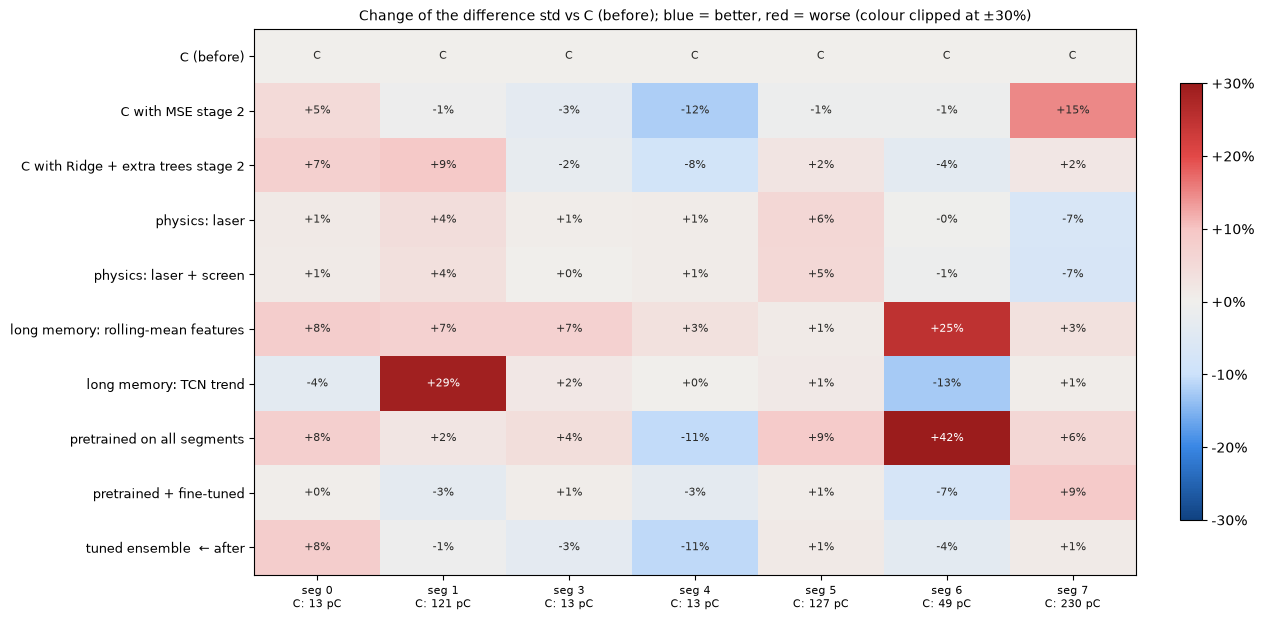

In [9]:
DIV = LinearSegmentedColormap.from_list("div", ["#104281", "#3987e5", "#cde2fb", "#f0efec", "#f6c6c5", "#e34948", "#9b1c1c"])
fig, ax = plt.subplots(figsize=(1.15 * len(segments) + 4.5, 0.45 * len(APPROACHES) + 1.6), layout="constrained")
lim = 0.3
im = ax.imshow(change.clip(-lim, lim), cmap=DIV, vmin=-lim, vmax=lim, aspect="auto")
for (i, j), v in np.ndenumerate(change.to_numpy()):
    ax.text(j, i, "C" if APPROACHES[i] == BEFORE else f"{v:+.0%}", ha="center", va="center", fontsize=8,
            color="white" if abs(v) > 0.2 else vd_plots.INK)
ax.set_xticks(range(len(segments)), [f"seg {k}\nC: {std_pc.loc[BEFORE, k]:.0f} pC" for k in segments], fontsize=8)
ax.set_yticks(range(len(APPROACHES)), [f"{a}  ← after" if a == AFTER else a for a in APPROACHES], fontsize=9)
ax.set_title("Change of the difference std vs C (before); blue = better, red = worse (colour clipped at ±30%)", fontsize=10)
fig.colorbar(im, ax=ax, shrink=0.8, format=plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
fig.savefig(FIGS / "change_vs_before.png", dpi=130, bbox_inches="tight");

In [10]:
detail = test[["bias [pC]", "slow [pC]", "fast [pC]", "fluct CCC"]].unstack("segment").loc[[BEFORE, AFTER]]
detail.style.format({col: ("{:.3f}" if col[0] == "fluct CCC" else "{:.1f}") for col in detail.columns}).set_caption(
    "before vs after: bias, slow (trend) and fast (shot-to-shot) part of the difference [pC], fluctuation CCC")

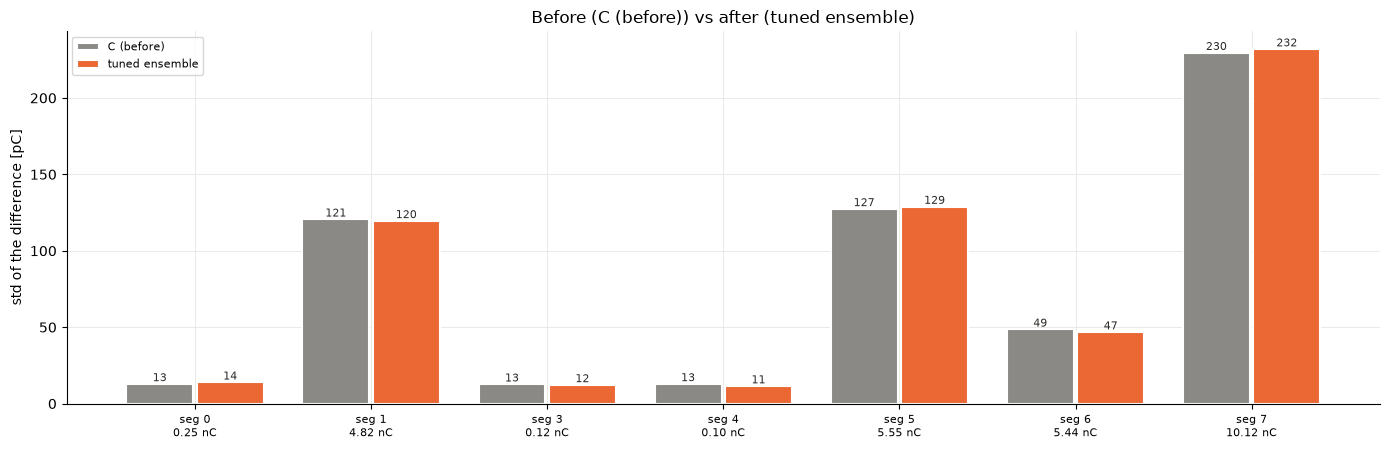

In [11]:
fig, ax = plt.subplots(figsize=(14, 4.6))
x = np.arange(len(segments))
for dx, name, color in [(-0.2, BEFORE, vd_plots.COMPARE), (0.2, AFTER, vd_plots.INFERRED)]:
    vals = [std_pc.loc[name, k] for k in segments]
    ax.bar(x + dx, vals, width=0.38, color=color, label=name, edgecolor="white", linewidth=1.5)
    for xi, v in zip(x + dx, vals):
        ax.text(xi, v, f"{v:.0f}", ha="center", va="bottom", fontsize=8, color=vd_plots.INK)
ax.set_xticks(x, [f"seg {k}\n{s['y'][s['test']].mean():.2f} nC" for k, s in segments.items()], fontsize=8)
ax.set(ylabel="std of the difference [pC]", title=f"Before ({BEFORE}) vs after ({AFTER})")
ax.legend(fontsize=8)
vd_plots.style(ax)
fig.tight_layout()
fig.savefig(FIGS / "before_after_std.png", dpi=130, bbox_inches="tight")

## Per segment: after (colour) vs before (grey)

In [12]:
frames = []
for k, s in segments.items():
    t = s["test"]
    frames.append(pd.DataFrame({"segment": k, "run": s["run"], "shot": np.flatnonzero(t), "measured": s["y"][t],
                                **{m: preds[k][m][t] for m in APPROACHES}}))
pred = pd.concat(frames)
pred.to_csv(OUT / "predictions_08_06.csv", index=False)

table = pd.concat({"before": vd_plots.summary_table(pred, BEFORE), "after": vd_plots.summary_table(pred, AFTER)}, axis=1)
cols = ["bias [pC]", "std diff [pC]", "95% of |diff| below [pC]", "max |diff| [pC]", "corr of fluctuations"]
table = table.loc[:, [(m, c) for c in cols for m in ["before", "after"]]]
table.style.format({col: vd_plots.TABLE_FORMAT[col[1]] for col in table.columns})

,before,after,before,after,before,after,before,after,before,after
,bias [pC],bias [pC],std diff [pC],std diff [pC],95% of |diff| below [pC],95% of |diff| below [pC],max |diff| [pC],max |diff| [pC],corr of fluctuations,corr of fluctuations
segment,,,,,,,,,,
0,-5.8,+15.4,12.9,14.0,27.6,37.9,64.5,64.4,0.84,0.84
1,-66.9,-71.1,120.6,119.6,279.6,279.8,920.3,877.9,0.76,0.74
3,-1.6,-0.4,12.7,12.3,26.6,25.2,104.8,103.0,0.63,0.63
4,-0.3,-1.5,12.9,11.5,26.0,23.1,62.6,63.3,0.66,0.65
5,+10.6,+4.2,127.4,129.0,285.7,281.1,949.0,1286.4,0.73,0.72
6,+0.9,-1.2,48.6,46.8,93.5,88.8,177.9,190.9,0.98,0.98
7,-57.0,-62.5,229.6,232.0,472.8,472.1,1663.7,1635.8,0.94,0.94


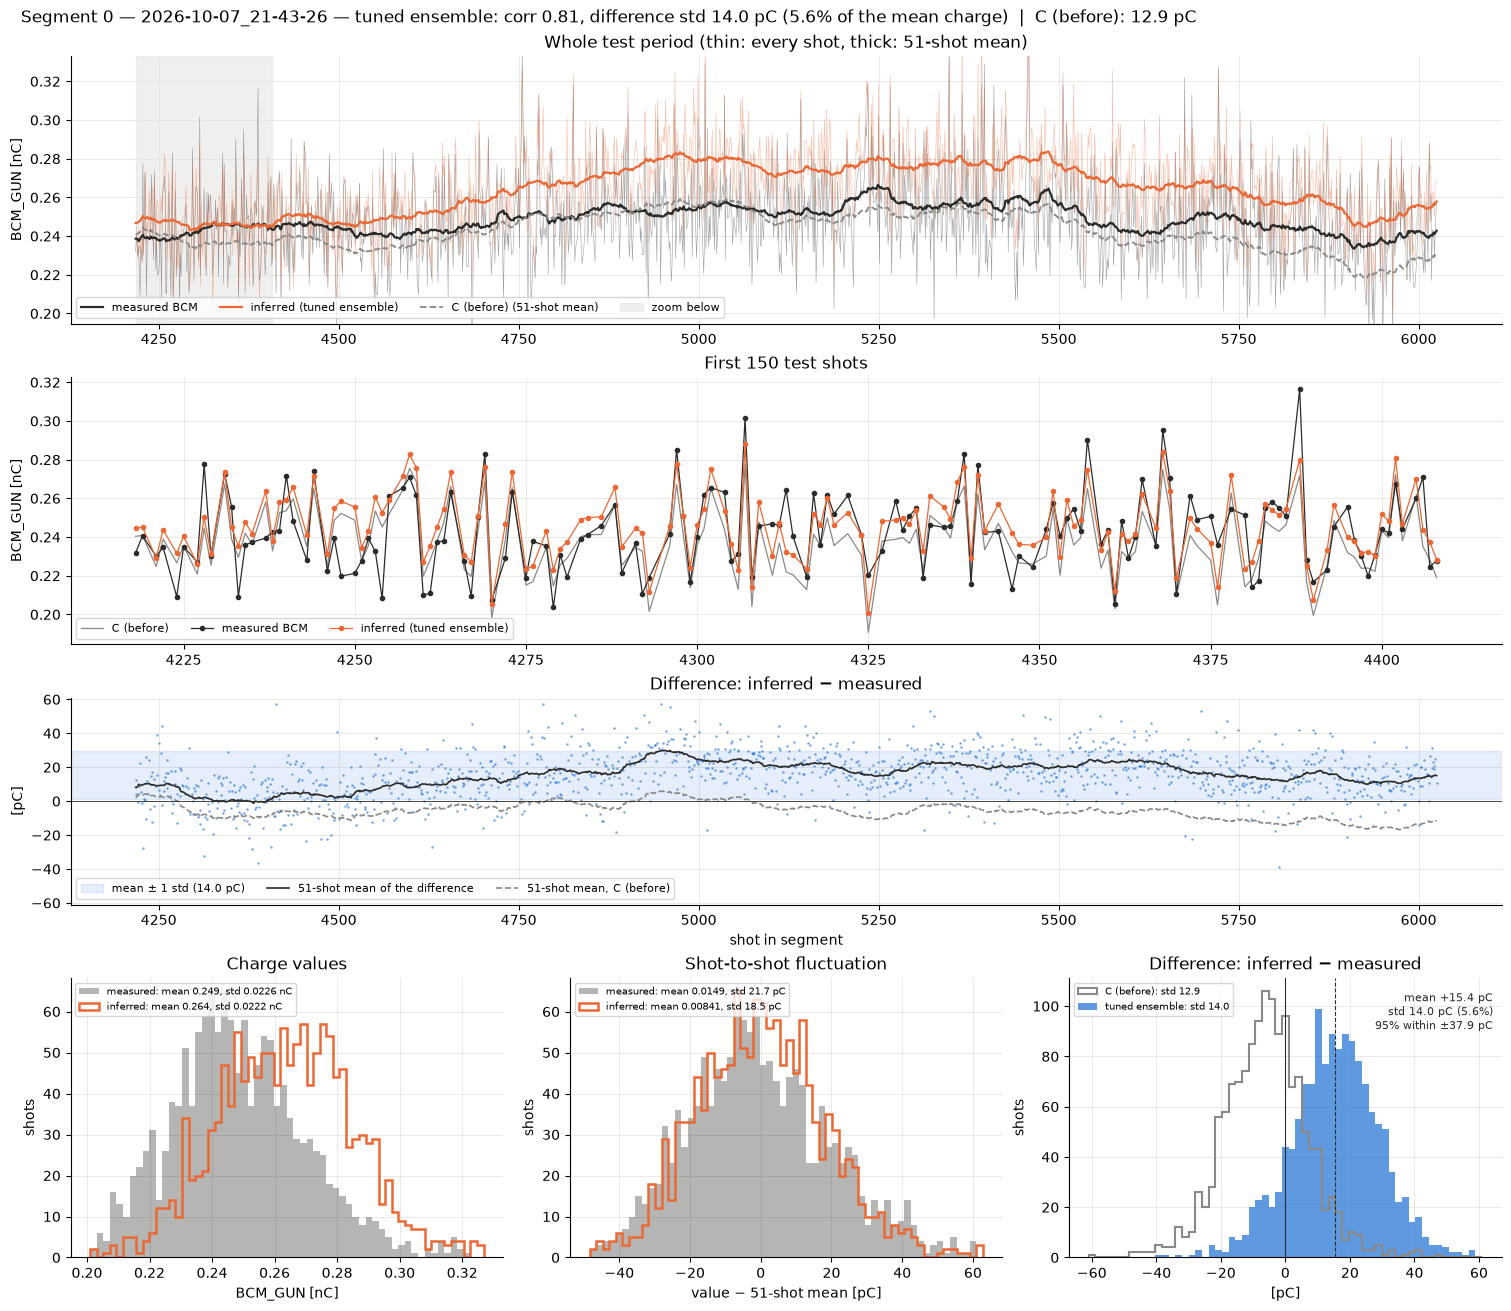

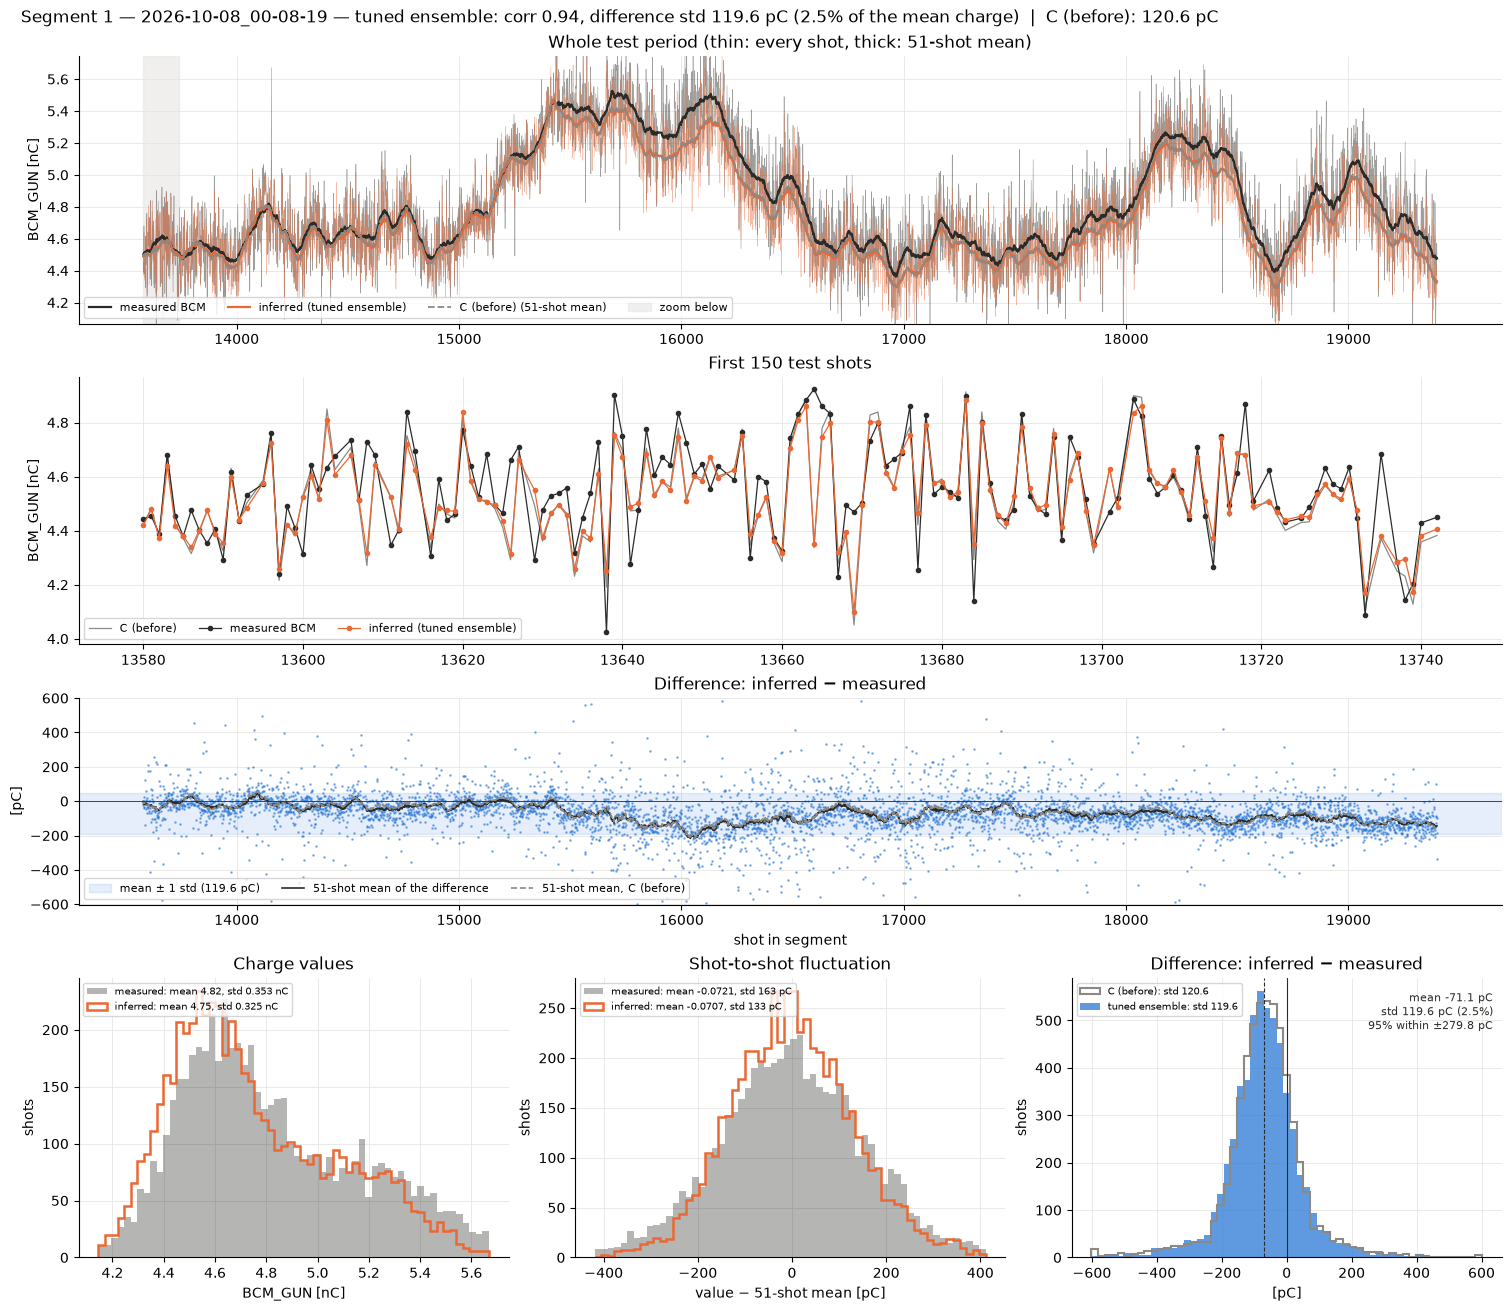

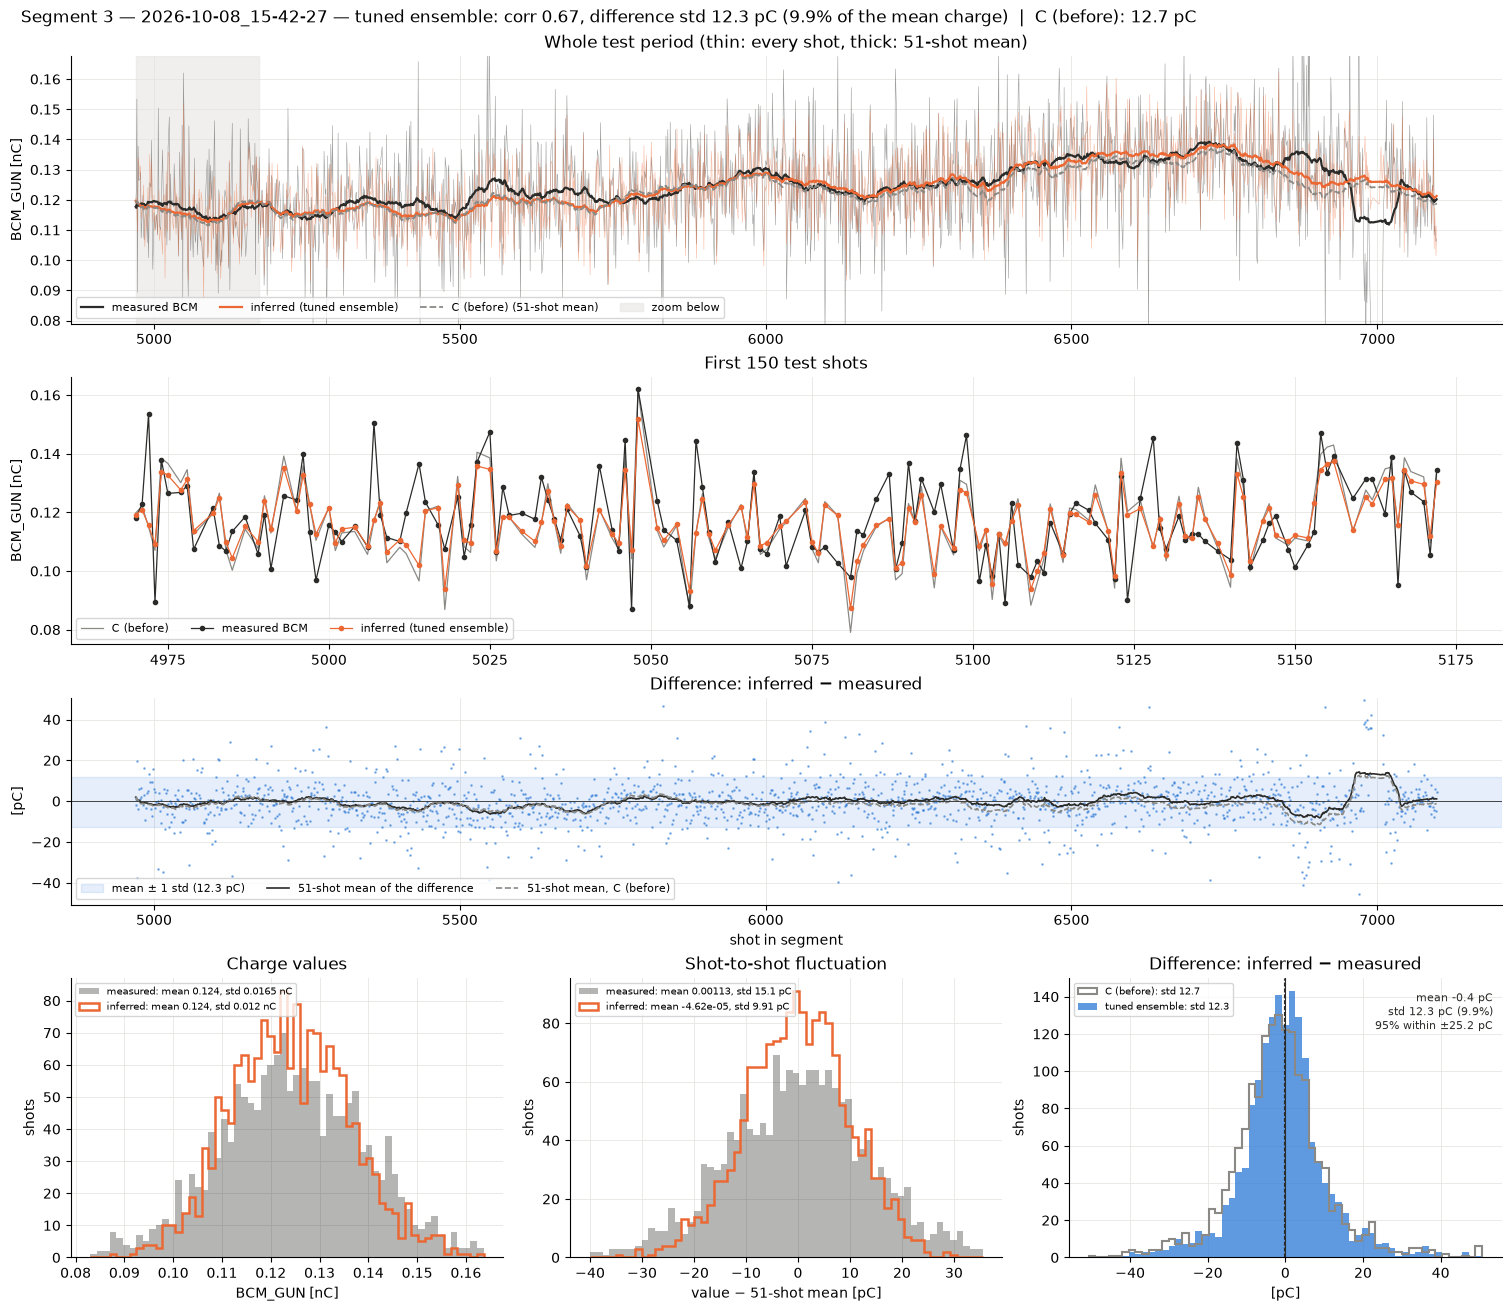

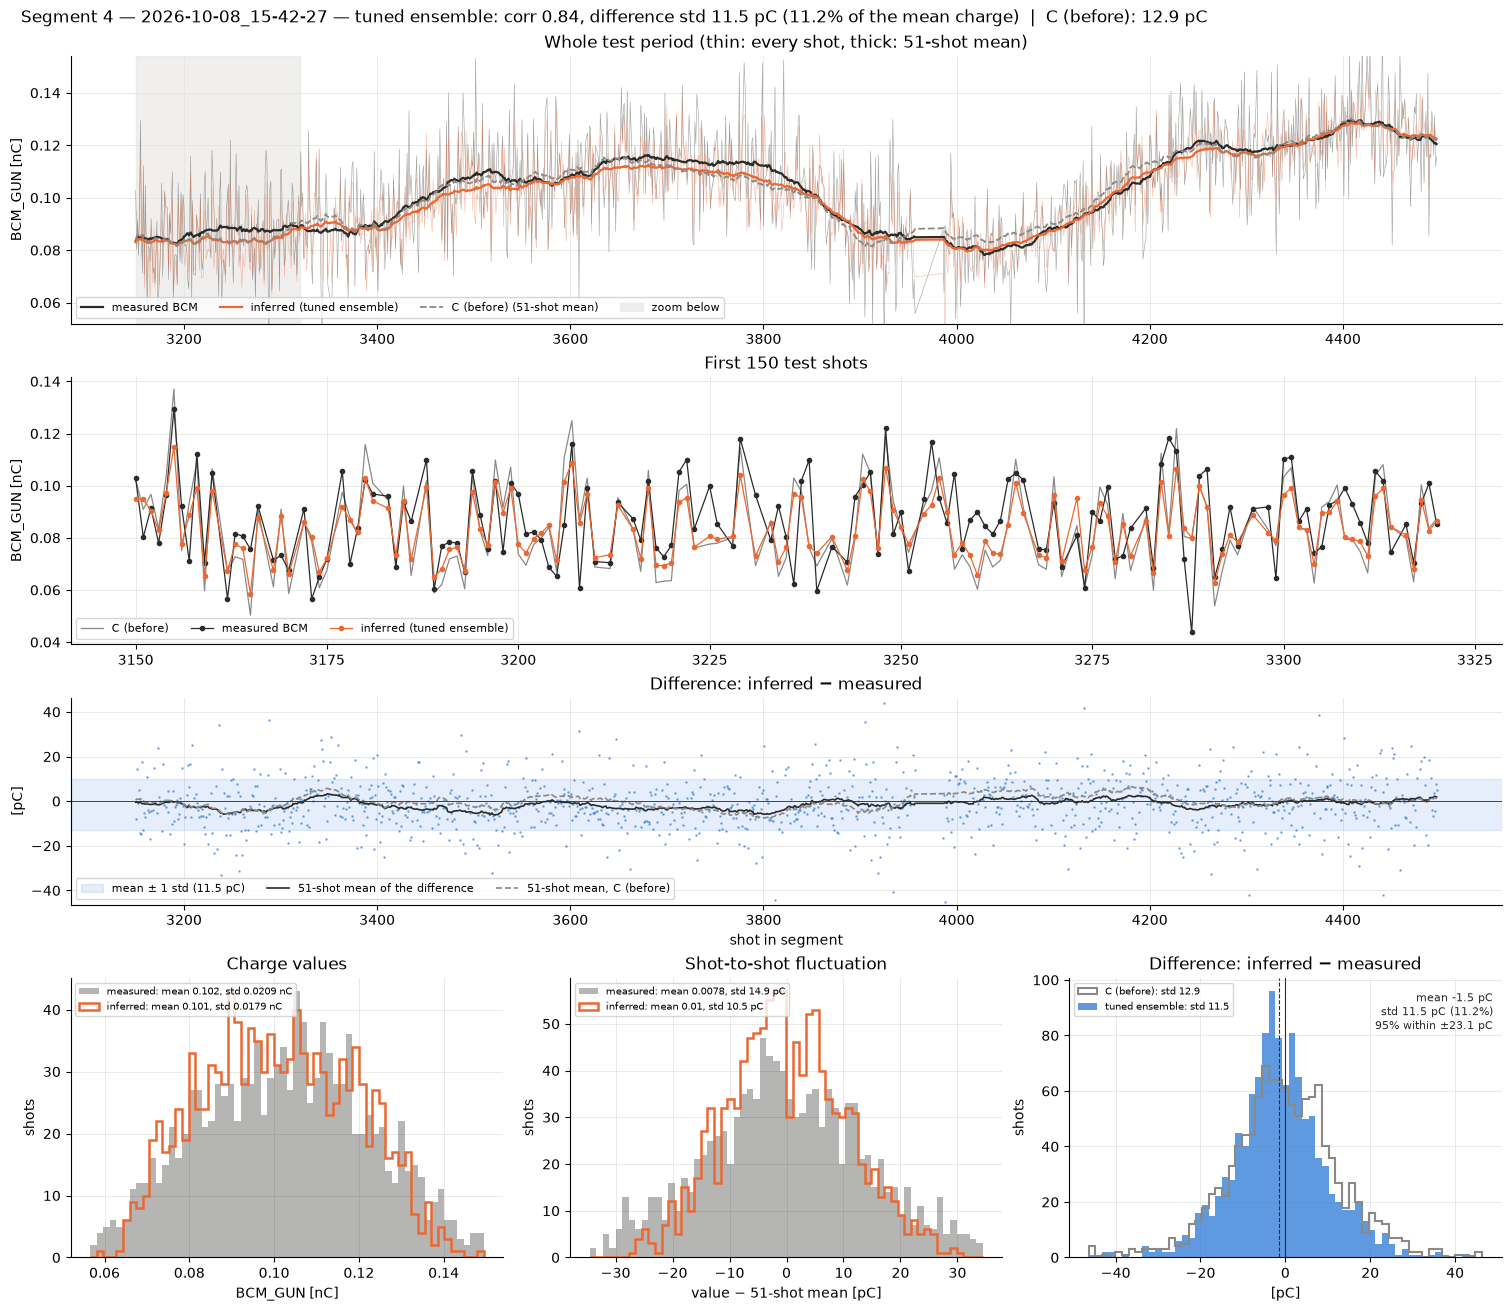

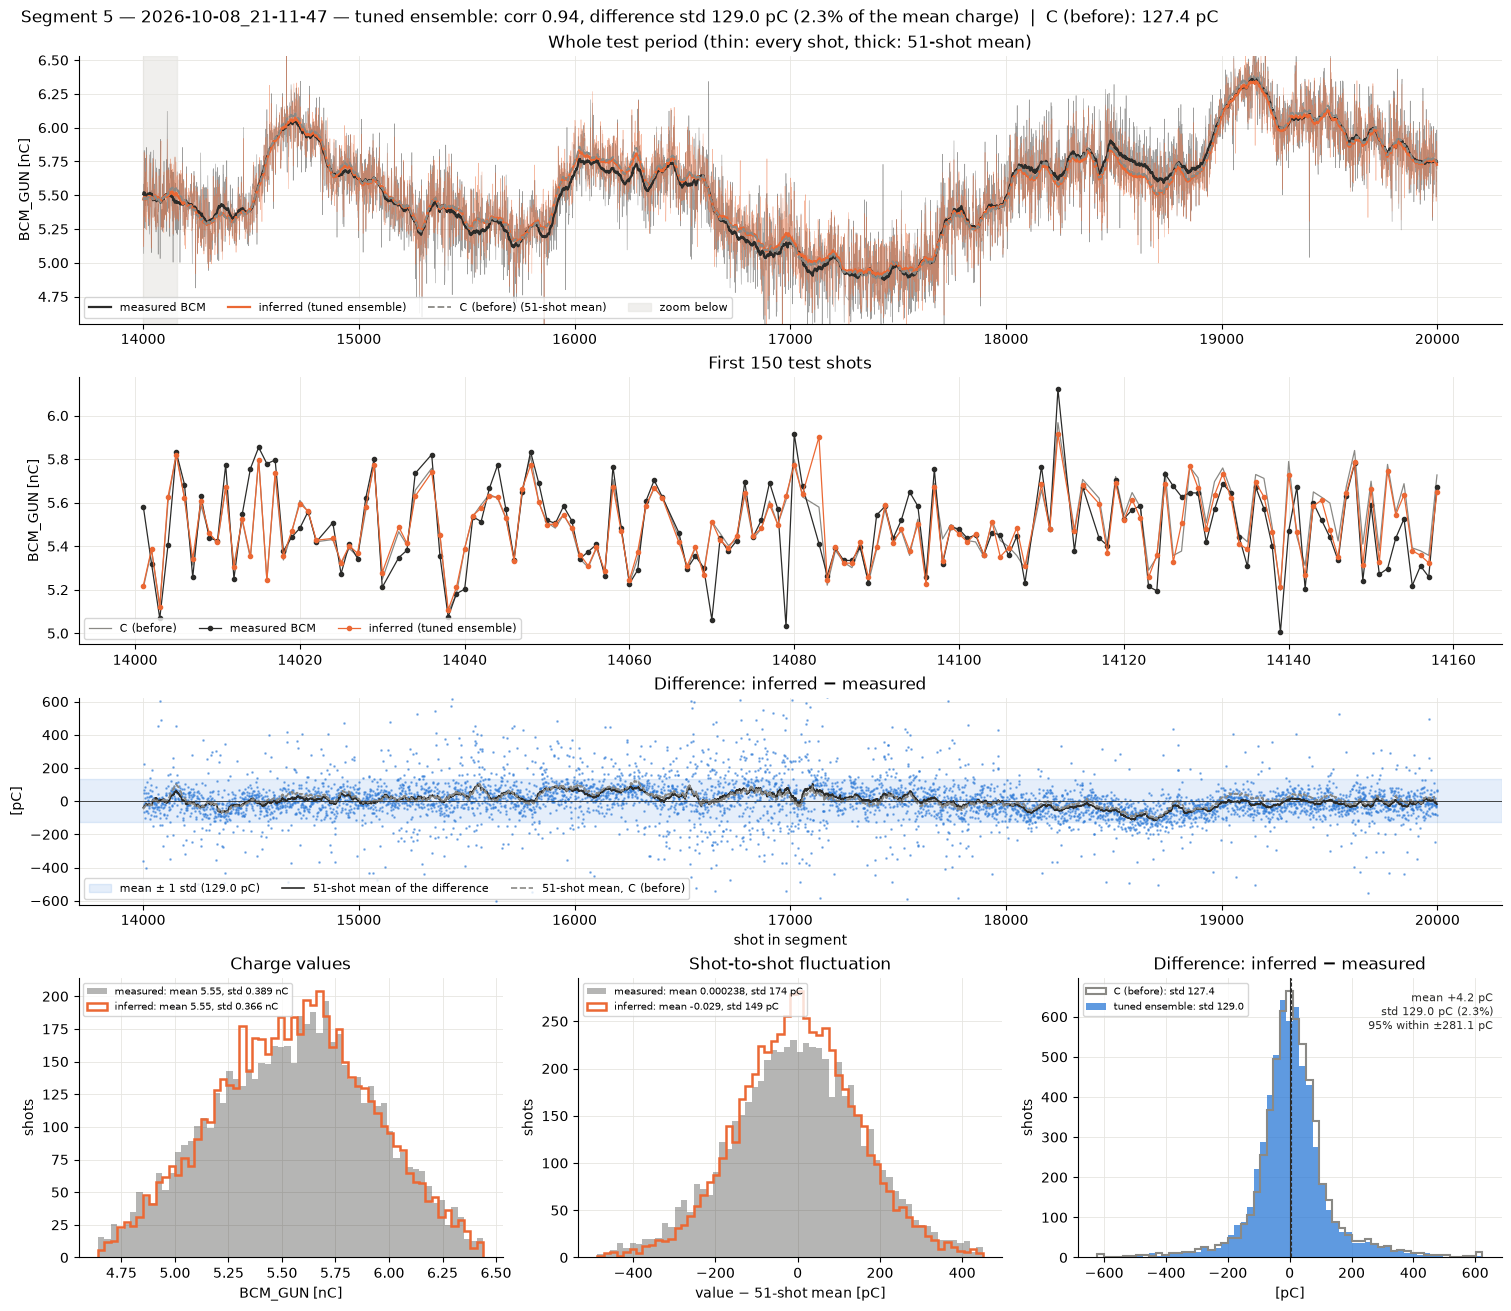

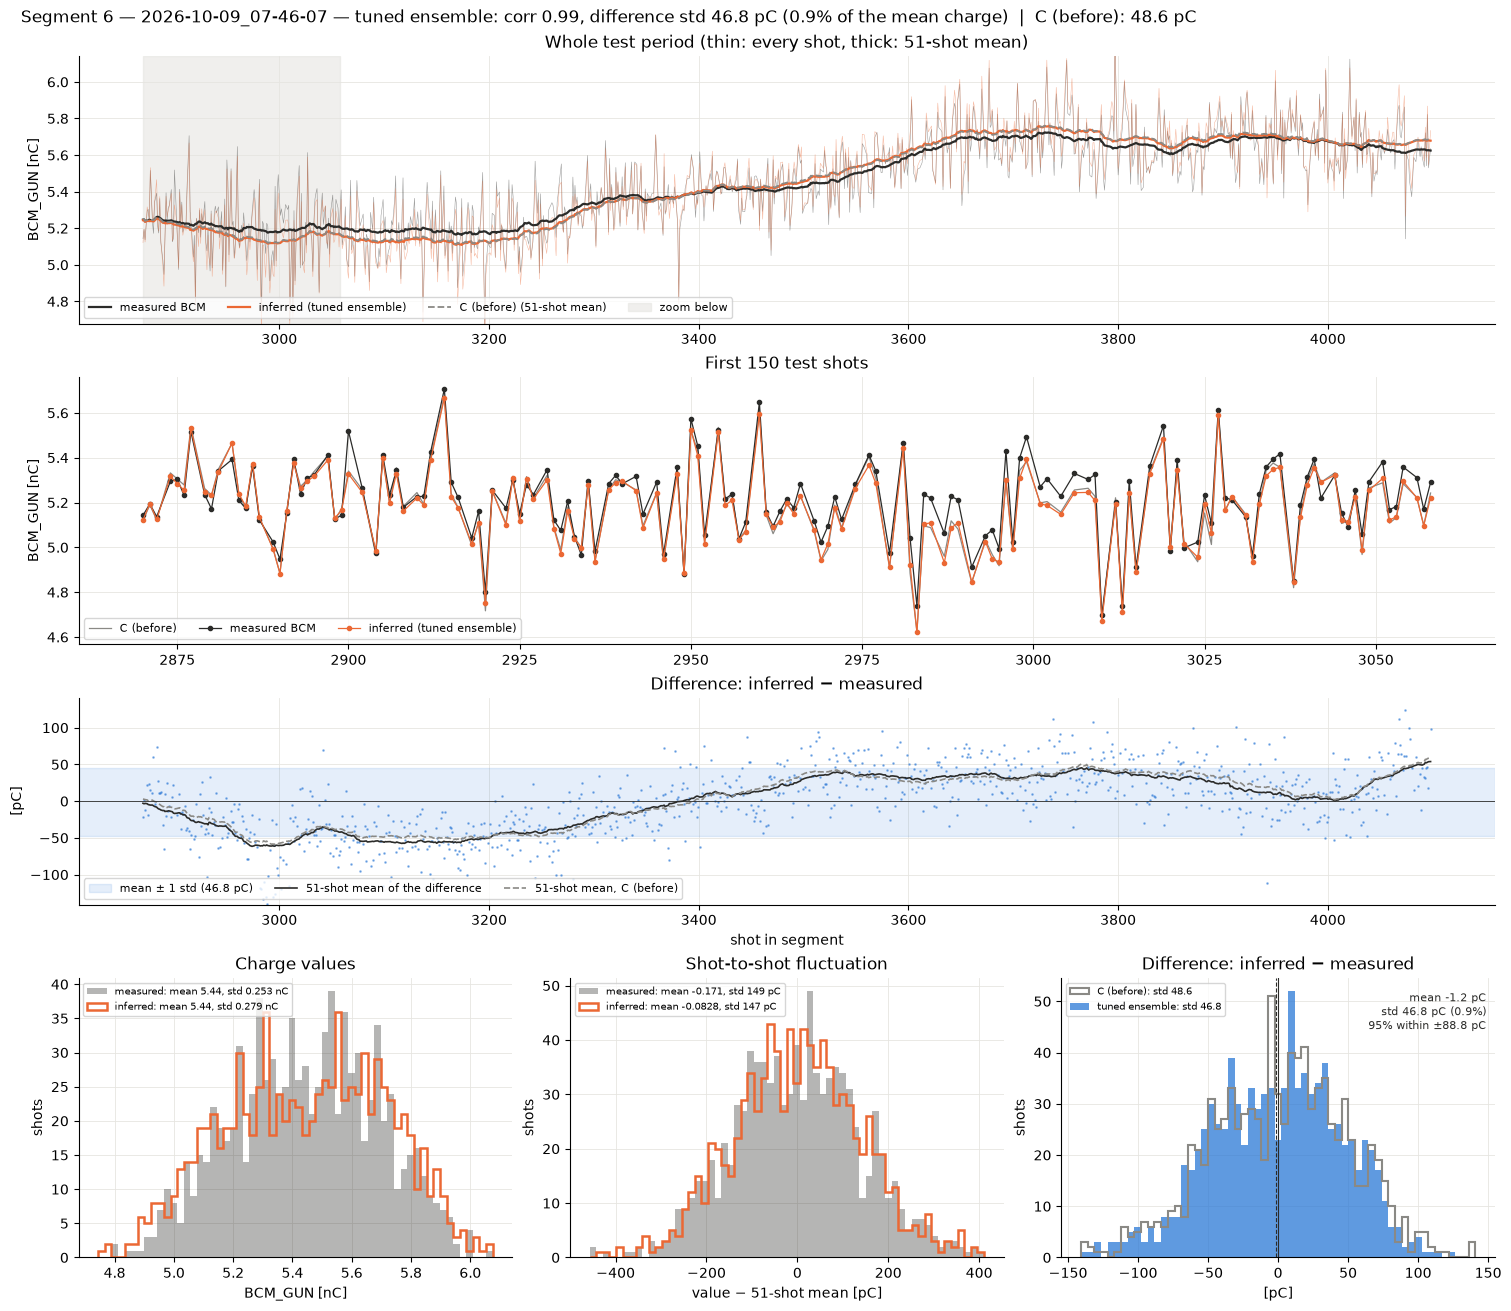

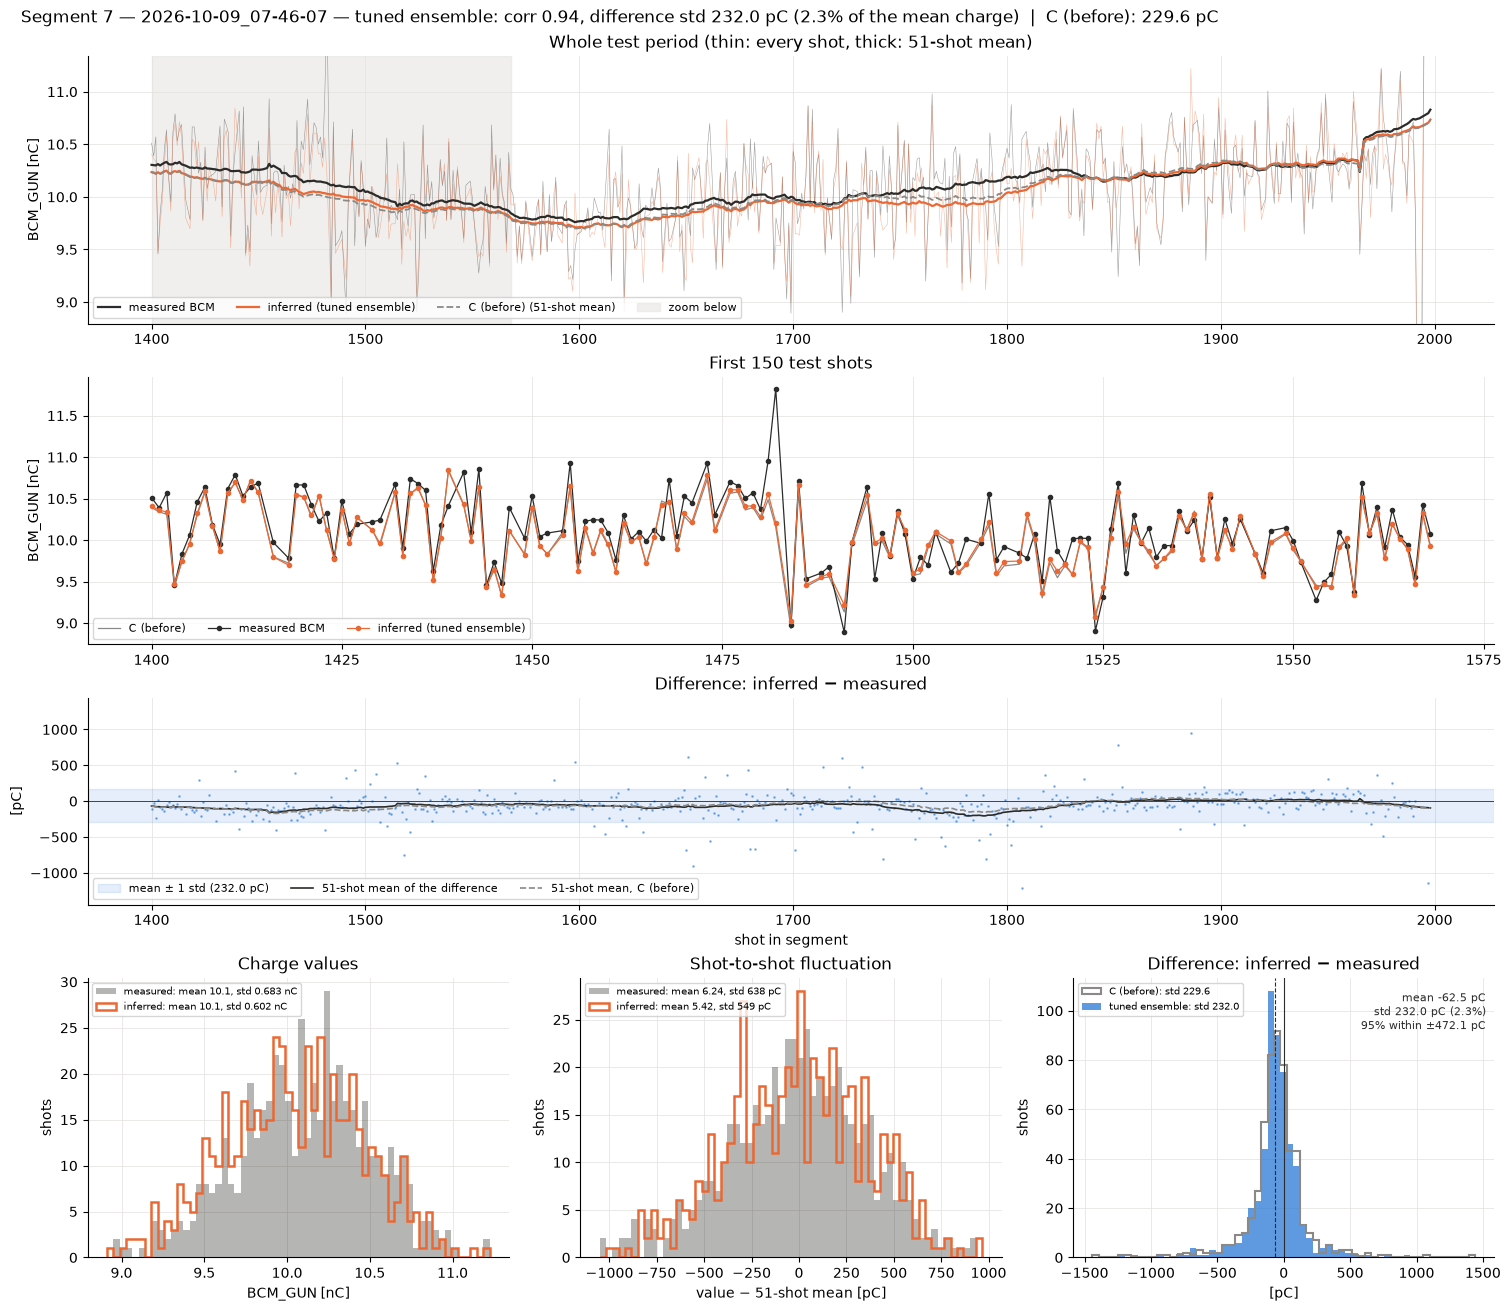

In [13]:
for k in segments:
    vd_plots.segment_figure(pred, k, AFTER, compare=BEFORE, save_dir=FIGS)

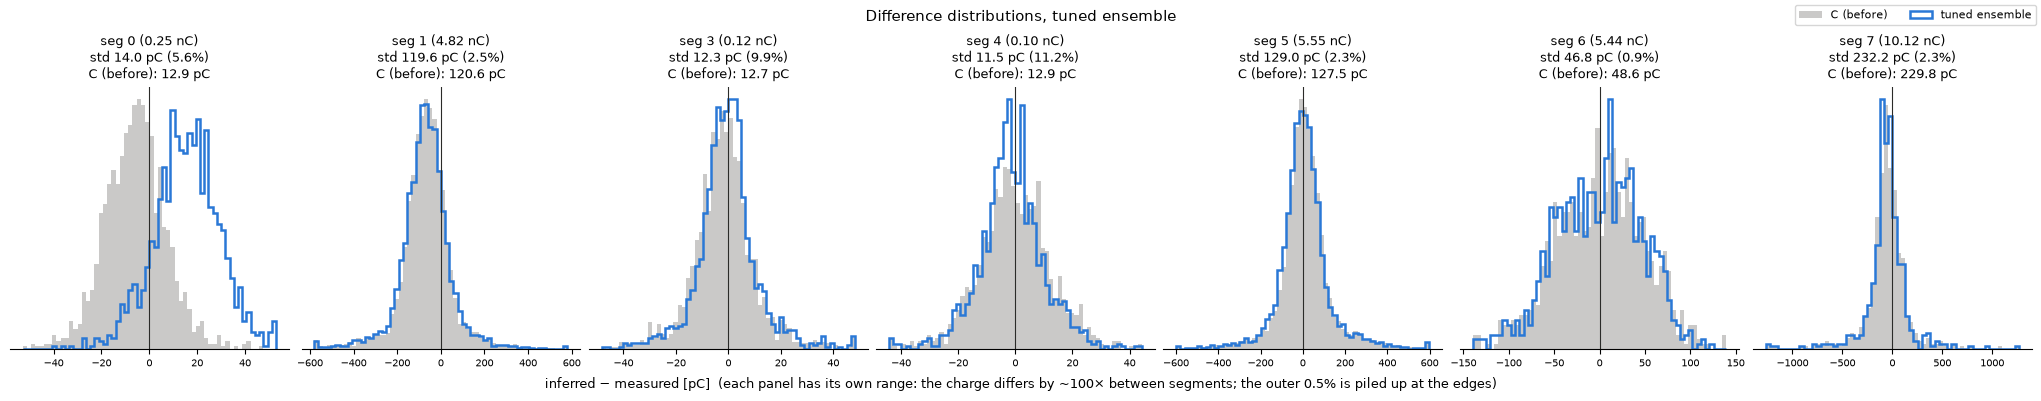

total 1417 s


In [14]:
vd_plots.difference_all_segments(pred, AFTER, compare=BEFORE, save_path=FIGS / "difference_all_segments.png")
print(f"total {time.time() - t0:.0f} s")